**Cell 1**

# Role 2 - Waveform simulation, injection, and label EDA

**Owner: Aaron Rassiq**

Create labeled observations from physical parameters and real noise. You own parameter draws, waveform generation, placement, target derivation, SNR accounting and accepted-population EDA. Your checkpoint deliverable is data evidence, not a trained model.

Revised scope: dataset preparation, preprocessing and EDA. This is a new notebook; earlier role notebooks are preserved. Every implementation cell is deliberately empty.

**Cell 2**

## What this milestone covers

The project question remains whether four-parameter inference generalizes from O3a H1 noise to O4a H1 noise. This checkpoint concentrates on preparing and understanding the dataset: source provenance, physical labels, preprocessing, actual split counts, EDA, plots, and limitations. Model training, model performance tables and calibration conclusions are outside this notebook set's required work.

The methodology section must still describe three algorithms because the rubric asks for a baseline and two improvements: linear regression, its small regularized extension Ridge, and SNPE with a masked autoregressive flow. Describe them as the next common comparison; do not invent new training results. Feature importance is explicitly requested by the rubric. Input-target association is useful EDA but does not fully substitute for model-based importance; Role 4 must state this gap honestly if importance is deferred.

**Existing evidence versus your work:** The repository already contains saved noise, injections and processed data. The revised PDF uses those artifacts, not results from these new notebooks. Your task is a separately identified manual pilot. Do not claim your pilot has the old dataset's 800-per-run counts until you actually generate and check them. The earlier split was a 750-row O3a development pool, 50 O3a held-out examples and 800 O4a evaluation examples. A 600/150 subdivision of the development pool is a proposal, not a completed split.

**Implementation rule:** Write your own code in the empty cells. You may call standard scientific libraries and consult their documentation, but do not import ligo_pipeline, project utils, config.py, another notebook's implementation, or prepared training/model checkpoints. Trusted raw strain with source metadata is allowed. You may write your own small functions after explaining their steps. No solution code is supplied here.

**Ownership:** Assign one person per notebook; names are unassigned. Review each other's outputs, but let each owner make their own notebook changes. Record actual contributions and dates. Every cell has a sequential cell_number and every markdown cell displays its number; the preceding task labels the empty code cell. Renumber all cells from 1 when inserting new cells. Execution counters are not stable cell numbering.


**Cell 3**

## Common contract and parallel work

Agree on one small experiment before scaling up: H1; O3a development and within-run evaluation; O4a cross-run evaluation; 4096 Hz; four-second final windows; a 35-350 Hz preprocessing band; target order chirp_mass, mass_ratio, chi_eff, distance. Keep any fixed-mass, distance-only exercise separate from this four-target pilot.

Use a new experiment_id and store files under artifacts/manual_preprocessing_milestone/<experiment_id>/. The role-owned subfolders are data/, simulation/, preprocessing/ and analysis/. Put experiment.json in data/ and repeat its ID and relevant settings in each output's metadata. Store raw segment duration, sample rate, waveform assumptions, parameter ranges, seeds, intended counts, actual counts and units. Do not overwrite the existing artifacts or the older role notebooks.

Role 1 supplies raw arrays, noise_id/group_id, source GPS intervals and source split assignments. Role 3 supplies noise-only PSD files early. Role 2 uses those PSDs for SNR selection, then supplies padded injected buffers, merger indices and labels. Role 3 supplies processed arrays and row metadata. Role 4 audits and combines evidence, counts and EDA; this role does not train the final models.

**Source-group separation:** Assign groups before simulation. Overlapping raw GPS intervals are one group even if filenames differ. Use train, validation, O3a_test and O4a_test split names; keep all O4a out of fitting and tuning. A recommended small design has at least three O3a training groups, one O3a validation group, one O3a test group and two O4a groups. Choose feasible durations and target counts together; these are planning suggestions, not completed allocations. If your pilot cannot support this design, document the limitation. Track nonoverlapping final crop windows as well as group identities.

**Handoff format:** Use .npy/.npz numeric arrays and .csv/.json metadata with repo-relative paths. Join per-example records by unique sample_id; join noise/PSD records by noise_id. Preserve run, split, group and units. Never assume two files have matching row order. Save rejection ledgers, shapes, dtypes, versions and seeds. Changes to schema/settings require all consumers to check compatibility.

**Start in parallel:** Role 1 can inspect one raw segment, Role 2 can inspect clean waveforms, Role 3 can validate sinusoids/FFT/filtering, and Role 4 can design the counting ledger, plot checklist and split audit. First integrate one real example end to end through data preparation. Then expand the pilot; no model fit is needed to check these handoffs.


**Cell 4**

## Your work boundary

**Inputs:** Role 1 raw noise and frozen source splits; Role 3 noise-only PSD files. Start independently with waveforms and a zero-noise or simple-noise practice buffer, clearly labeled as an exercise.

**Outputs:** simulation/injection_manifest.csv; simulation/attempts.csv; simulation/buffers/<sample_id>.npy; simulation/targets.csv; population/SNR figures and simulation notes. Keep full padded buffers for Role 3, not final cropped windows.

**Start in parallel:** Draw parameter tables and compare clean waveforms immediately. Practice alignment on a small known array. Role 3 supplies an early PSD artifact; use it for a small real-noise pilot before increasing the number of attempts. Do not estimate production PSDs here.

**File contract:** injection_manifest.csv: sample_id, noise_id, group_id, run, split, buffer_path, buffer_start_in_noise_samples, buffer_n_samples, merger_index_in_buffer, waveform_start_in_buffer, waveform_n_samples, snr, status. targets.csv: sample_id, mass_1, mass_2, chi_1, chi_2, distance, chirp_mass, mass_ratio, chi_eff. attempts.csv also records rejected/failed attempts and reasons. The inherited split cannot be changed.

All paths use the experiment-specific root in the common contract above. Older path wording in conceptual examples does not authorize writing into historical artifact folders.

**Cell 5**

## Task 1: Define a physical pilot and draw parameters

### Background knowledge
A prior is the distribution of physical parameters before seeing data. Sorting component masses enforces m1 >= m2. A distance draw proportional to d squared is Euclidean volume weighting; it is not an exact cosmological comoving-volume calculation. Derived targets are usually not uniform even if components are.

### Your task
Choose and record mass, aligned-spin and distance ranges. Match the existing ranges if feasible: 5-100 solar masses, spins 0-0.8, distance 100-2000 Mpc. Write the draw yourself, fix a seed, and create at least 100 practice rows. Explain any narrower pilot range. Discuss with Role 4 how the simulation distribution relates to an inference prior.

### Evidence and completion checks
Prior table, parameter bounds, units and empirical histograms; no claim of uniform derived targets.

**Cell 6 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

/opt/homebrew/Cellar/python@3.11/3.11.16/Frameworks/Python.framework/Versions/3.11/lib/python3.11/importlib/__init__.py:126: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  return _bootstrap._gcd_import(name[level:], package, level)


        Parameter  minimum  maximum          Units  \
0  mass_1, mass_2        5    100.0   solar masses   
1    chi_1, chi_2        0      0.8  dimensionless   
2        distance      100   2000.0            Mpc   

                           Distribution  
0  Uniform component draws, then sorted  
1                               uniform  
2             Euclidean volume weighted  
        draw_id     mass_1     mass_2     chi_1     chi_2     distance
0  practice-000  97.786478  33.294809  0.597819  0.457930  1004.417233
1  practice-001  63.820297  41.118595  0.001657  0.392815  1467.487686
2  practice-002  92.708392  33.666956  0.647485  0.575751  1942.092253
3  practice-003  29.860780  21.610413  0.645447  0.371029  1821.358071
4  practice-004  52.072994  35.314221  0.043626  0.680891   796.115899


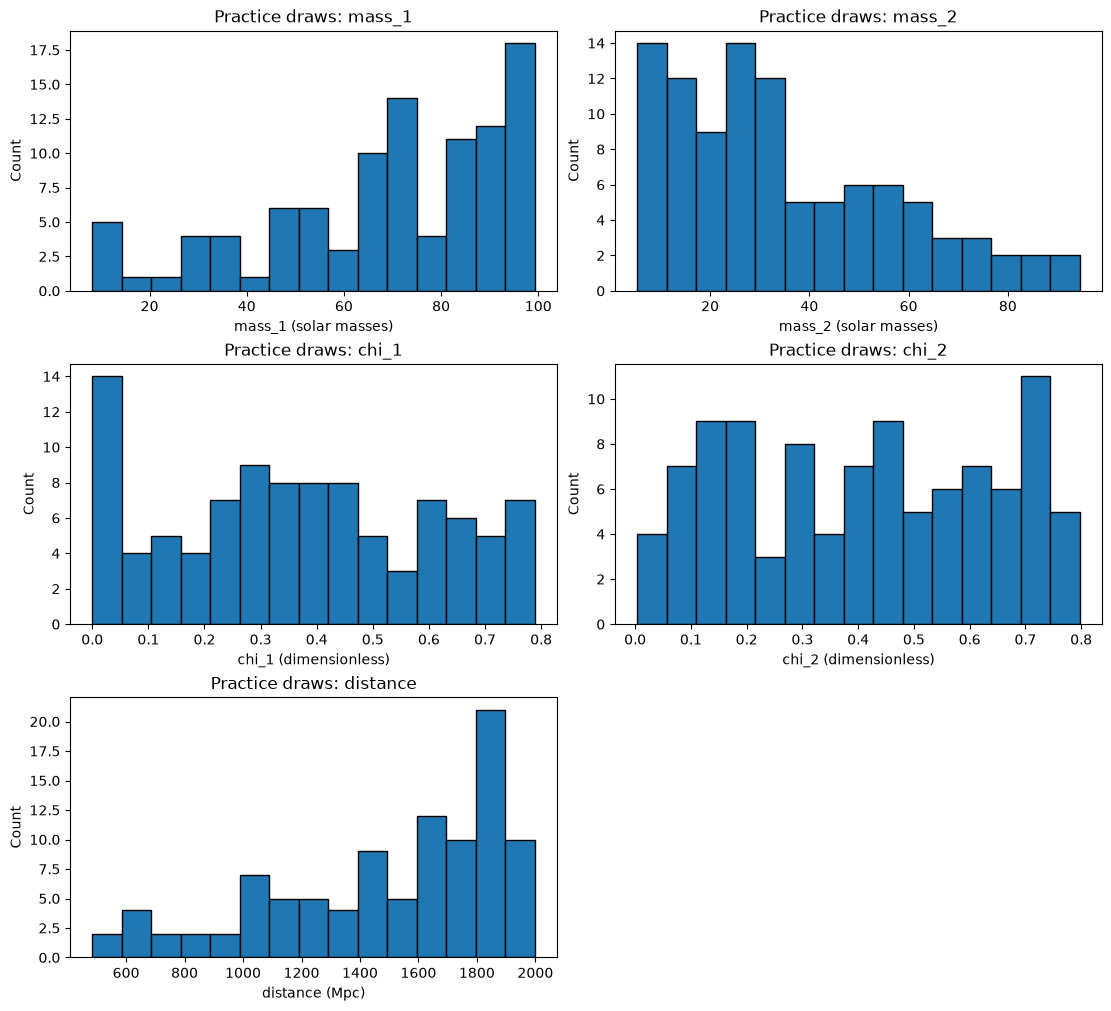

In [1]:
# to load noise from 01: noise = np.load(strain_path)
import numpy as np 
import pandas as pd 
from pycbc.waveform import get_td_waveform
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

SOLAR_MASS_RANGE = (5,100)
SPIN_RANGE = (0, 0.8)
DISTANCE_RANGE = (100, 2000)
SEED = 1234
N_PRACTICE_DRAWS = 100

rng = np.random.default_rng(SEED)

'''
Create the priors table
'''

priors_table = {
    'Parameter': ['mass_1, mass_2', 'chi_1, chi_2', 'distance'],
    'minimum': [5,0,100],
    'maximum': [100,0.8,2000],
    'Units': ['solar masses', 'dimensionless', 'Mpc'],
    'Distribution': ['Uniform component draws, then sorted', 'uniform', 'Euclidean volume weighted']
}

priors_table_df = pd.DataFrame(priors_table)
print(priors_table_df)

'''
Mass Function
'''

def sample_mass(n:int, minimum:int, maximum:int) -> np.ndarray:
    return  rng.uniform(low=minimum,high=maximum,size = n)

raw_m_1 = sample_mass(N_PRACTICE_DRAWS, SOLAR_MASS_RANGE[0], SOLAR_MASS_RANGE[1])
raw_m_2 = sample_mass(N_PRACTICE_DRAWS, SOLAR_MASS_RANGE[0], SOLAR_MASS_RANGE[1])

assert np.all((raw_m_1 >= SOLAR_MASS_RANGE[0]) & (raw_m_2 >= SOLAR_MASS_RANGE[0]))
assert np.all((raw_m_1 <= SOLAR_MASS_RANGE[1]) & (raw_m_2 <= SOLAR_MASS_RANGE[1]))

mass_1 = np.maximum(raw_m_1, raw_m_2)
mass_2 = np.minimum(raw_m_1, raw_m_2)

assert np.all(mass_1 >= mass_2)

'''
Spin Function
'''

def sample_chi(n:int, minimum:int, maximum:int): #chi = dimensionless spins
    return  rng.uniform(low=minimum,high=maximum,size = n)

chi_1 = sample_chi(N_PRACTICE_DRAWS, SPIN_RANGE[0], SPIN_RANGE[1])
chi_2 = sample_chi(N_PRACTICE_DRAWS, SPIN_RANGE[0], SPIN_RANGE[1])

assert np.all((chi_1 >= SPIN_RANGE[0]) & (chi_2 >= SPIN_RANGE[0]))
assert np.all((chi_1 <= SPIN_RANGE[1]) & (chi_2 <= SPIN_RANGE[1]))

'''
Distance Function
'''

def sample_distance(n:int, minimum:int, maximum:int):
    u = rng.uniform(0,1, size=n)
    return np.cbrt((u*(maximum**3 - minimum**3)) + minimum**3)

distance = sample_distance(N_PRACTICE_DRAWS, DISTANCE_RANGE[0], DISTANCE_RANGE[1])

assert np.all(distance >= 100)
assert np.all(distance <= 2000)

'''
Parameter Table
'''

params = {
    "draw_id": [f"practice-{index:03d}" for index in range(N_PRACTICE_DRAWS)],
    'mass_1': mass_1,
    'mass_2': mass_2,
    'chi_1': chi_1,
    'chi_2': chi_2,
    'distance': distance,
}

parameter_table = pd.DataFrame(params)
assert parameter_table.notna().all().all()

print(parameter_table.head())

import matplotlib.pyplot as plt

plot_columns = [
    "mass_1",
    "mass_2",
    "chi_1",
    "chi_2",
    "distance",
]

figure, axes = plt.subplots(
    3,
    2,
    figsize=(11, 10),
    constrained_layout=True,
)

units = {
    "mass_1": "solar masses",
    "mass_2": "solar masses",
    "chi_1": "dimensionless",
    "chi_2": "dimensionless",
    "distance": "Mpc",
}

for axis, column in zip(axes.flat, plot_columns):
    axis.hist(
        parameter_table[column],
        bins=15,
        edgecolor="black",
    )
    axis.set_title(f"Practice draws: {column}")
    axis.set_xlabel(f"{column} ({units[column]})")
    axis.set_ylabel("Count")

axes.flat[-1].axis("off")
plt.show()



**Cell 7**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

On October 18, 2026, I defined the manual pilot priors and generated 100 reproducible parameter draws using seed 1234. Component masses were independently drawn from 5-100 solar masses and sorted so mass_1 >= mass_2. Aligned dimensionless spins were drawn uniformly from 0-0.8, while distance was drawn from a Euclidean-volume-weighted distribution from 100-2000 Mpc. The unique practice IDs run from practice-000 through practice-099. Assertions confirmed the mass ordering, parameter bounds and absence of missing values. The five histograms show the expected sorted-mass shapes, approximately uniform component-spin draws and a distance distribution weighted toward larger distances. These are simulator priors rather than measured astrophysical population distributions. I will hand the parameter and derived-target tables to the injection and selection steps. Production IDs are assigned only to accepted injections.

**Cell 8**

## Task 2: Explore waveform physics before injection

### Background knowledge
IMRPhenomD models aligned-spin inspiral, merger and ringdown. h_plus and h_cross are polarizations, not automatically the detector response. At fixed remaining parameters, amplitude scales approximately as 1/distance. For a learning pilot, using h_plus directly is a simplified convention that must be documented.

### Your task
Call the waveform library directly. Inspect time spacing, duration and peak location. Compare distances 100, 500 and 1000 Mpc with identical masses/spins and a common vertical scale. Vary mass separately. Agree on a fixed inclination/polarization convention; do not claim a full detector projection if you use plus-only.

### Evidence and completion checks
Clean-waveform comparison figure with correct time/strain axes and an explanation of amplitude versus timing changes.

**Cell 9 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

Reference samples: 65536
Sample spacing: 0.000244140625 seconds
Returned array duration: 16.0 seconds
Peak index: 45036
Peak time: -0.0048828125 seconds
Peak absolute strain: 1.5352438932056834e-21


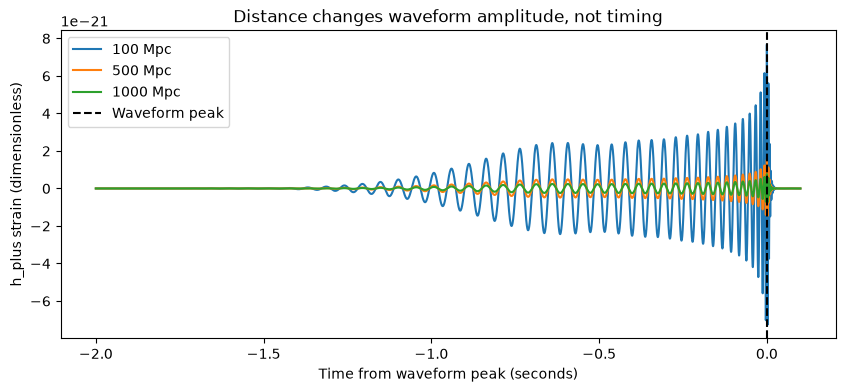

,distance_Mpc,peak_strain,visible_chirp_duration_sec
0,100,7.676219e-21,1.662354
1,500,1.535244e-21,1.662354
2,1000,7.676219e-22,1.662354


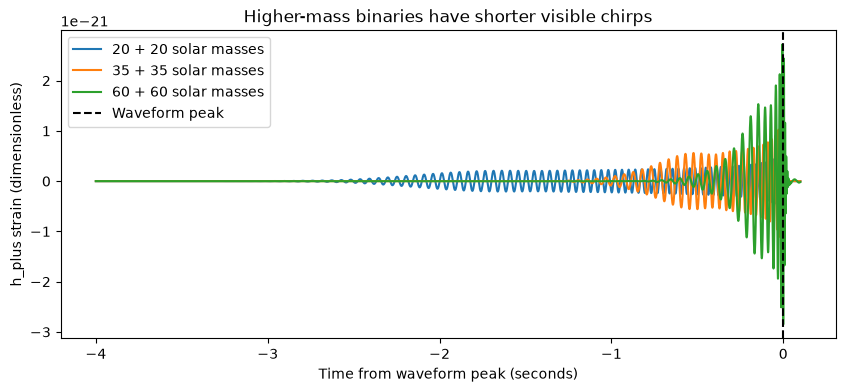

,mass_1_solar_masses,mass_2_solar_masses,peak_strain,visible_chirp_duration_sec
0,20,20,9.478830e-22,3.140869
1,35,35,1.666843e-21,1.539795
2,60,60,2.852241e-21,0.930664


In [2]:
from pycbc.waveform import get_td_waveform

SAMPLE_RATE_HZ = 4096
DELTA_T_SEC = 1 / SAMPLE_RATE_HZ
F_LOWER_HZ = 20
WAVEFORM_APPROXIMANT = "IMRPhenomD"

REFERENCE_MASS_1 = 35
REFERENCE_MASS_2 = 30
REFERENCE_CHI_1 = 0.2
REFERENCE_CHI_2 = 0.1
REFERENCE_DISTANCE_MPC = 500


def create_waveform(
        mass1=REFERENCE_MASS_1,
        mass2=REFERENCE_MASS_2,
        spin1z=REFERENCE_CHI_1,
        spin2z=REFERENCE_CHI_2,
        distance=REFERENCE_DISTANCE_MPC,
        ):
    hp, hc = get_td_waveform(
        approximant=WAVEFORM_APPROXIMANT,
        mass1=mass1,
        mass2=mass2,
        spin1z=spin1z,
        spin2z=spin2z,
        distance=distance,
        inclination=0,
        coa_phase=0,
        delta_t=DELTA_T_SEC,
        f_lower=F_LOWER_HZ,
    )

    waveform = hp.numpy()
    peak_index = int(np.argmax(np.abs(waveform)))
    peak_amplitude = float(np.max(np.abs(waveform)))
    time_from_peak_sec = (
        np.arange(len(waveform)) - peak_index
    ) * DELTA_T_SEC

    # The returned arrays contain padding, so this measures the visible
    # chirp using one consistent relative-amplitude threshold.
    visible = np.flatnonzero(
        np.abs(waveform[:peak_index + 1]) >= peak_amplitude * 1e-3
    )
    visible_chirp_duration_sec = (
        peak_index - visible[0]
    ) * DELTA_T_SEC

    assert waveform.ndim == 1
    assert len(waveform) > 0
    assert np.isfinite(waveform).all()
    assert np.isclose(float(hp.delta_t), DELTA_T_SEC)
    assert 0 <= peak_index < len(waveform)

    return {
        "hp": hp,
        "hc": hc,
        "waveform": waveform,
        "time_from_peak_sec": time_from_peak_sec,
        "n_samples": len(waveform),
        "array_duration_sec": len(waveform) * DELTA_T_SEC,
        "peak_index": peak_index,
        "peak_time_sec": float(hp.sample_times[peak_index]),
        "peak_amplitude": peak_amplitude,
        "visible_chirp_duration_sec": visible_chirp_duration_sec,
    }


reference = create_waveform()
print("Reference samples:", reference["n_samples"])
print("Sample spacing:", DELTA_T_SEC, "seconds")
print("Returned array duration:", reference["array_duration_sec"], "seconds")
print("Peak index:", reference["peak_index"])
print("Peak time:", reference["peak_time_sec"], "seconds")
print("Peak absolute strain:", reference["peak_amplitude"])


distance_results = {}
for current_distance in [100, 500, 1000]:
    distance_results[current_distance] = create_waveform(
        distance=current_distance
    )

plt.figure(figsize=(10, 4))
for current_distance, result in distance_results.items():
    view_mask = (
        (result["time_from_peak_sec"] >= -2)
        & (result["time_from_peak_sec"] <= 0.1)
    )
    plt.plot(
        result["time_from_peak_sec"][view_mask],
        result["waveform"][view_mask],
        label=f"{current_distance} Mpc",
    )
plt.axvline(0, color="black", linestyle="--", label="Waveform peak")
plt.title("Distance changes waveform amplitude, not timing")
plt.xlabel("Time from waveform peak (seconds)")
plt.ylabel("h_plus strain (dimensionless)")
plt.legend()
plt.show()

distance_summary = pd.DataFrame([
    {
        "distance_Mpc": current_distance,
        "peak_strain": result["peak_amplitude"],
        "visible_chirp_duration_sec": result["visible_chirp_duration_sec"],
    }
    for current_distance, result in distance_results.items()
])
display(distance_summary)

assert np.isclose(
    distance_results[100]["peak_amplitude"]
    / distance_results[500]["peak_amplitude"],
    5,
    rtol=0.01,
)
assert np.isclose(
    distance_results[500]["peak_amplitude"]
    / distance_results[1000]["peak_amplitude"],
    2,
    rtol=0.01,
)


mass_results = {}
for mass_pair in [(20, 20), (35, 35), (60, 60)]:
    mass_results[mass_pair] = create_waveform(
        mass1=mass_pair[0],
        mass2=mass_pair[1],
    )

plt.figure(figsize=(10, 4))
for mass_pair, result in mass_results.items():
    view_mask = (
        (result["time_from_peak_sec"] >= -4)
        & (result["time_from_peak_sec"] <= 0.1)
    )
    plt.plot(
        result["time_from_peak_sec"][view_mask],
        result["waveform"][view_mask],
        label=f"{mass_pair[0]} + {mass_pair[1]} solar masses",
    )
plt.axvline(0, color="black", linestyle="--", label="Waveform peak")
plt.title("Higher-mass binaries have shorter visible chirps")
plt.xlabel("Time from waveform peak (seconds)")
plt.ylabel("h_plus strain (dimensionless)")
plt.legend()
plt.show()

mass_summary = pd.DataFrame([
    {
        "mass_1_solar_masses": mass_pair[0],
        "mass_2_solar_masses": mass_pair[1],
        "peak_strain": result["peak_amplitude"],
        "visible_chirp_duration_sec": result["visible_chirp_duration_sec"],
    }
    for mass_pair, result in mass_results.items()
])
display(mass_summary)

assert mass_summary["peak_strain"].is_monotonic_increasing
assert mass_summary["visible_chirp_duration_sec"].is_monotonic_decreasing


**Cell 10**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

On October 18, 2026, I generated clean IMRPhenomD waveforms at 4,096 Hz with a 20 Hz lower cutoff. I fixed inclination and coalescence phase at zero and used h_plus directly, so this is a face-on plus-polarization convention rather than a full H1 antenna projection. With masses and spins fixed, the peak strain at 100 Mpc was five times the value at 500 Mpc, while the 500 Mpc value was twice the value at 1,000 Mpc, confirming the expected inverse-distance scaling. Distance changed amplitude without changing waveform timing. In the separate mass comparison, increasing equal component masses from 20+20 to 60+60 solar masses increased peak strain and reduced the visible pre-merger chirp duration. The 16-second returned arrays contain padding, so visible duration was measured consistently from the first sample above 0.1% of peak strain to the peak. These clean waveforms will be handed to the alignment and injection step.

**Cell 11**

## Task 3: Derive the four targets

### Background knowledge
Chirp mass Mc = (m1*m2)^(3/5)/(m1+m2)^(1/5), mass ratio q = m2/m1, and effective spin chi_eff = (m1*chi1+m2*chi2)/(m1+m2). Distance is kept in Mpc. These labels come from the simulator, not measured noise.

### Your task
Compute the target table yourself. Audit mass ordering and formula results on a few simple manually checked cases. Preserve sample IDs and the shared target order. Explain why pure noise does not have a distance/mass label of zero.

### Evidence and completion checks
Finite target table with units, range checks and manually verified examples.

**Cell 12 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

In [3]:
TARGET_ORDER = [
    "chirp_mass",
    "mass_ratio",
    "chi_eff",
    "distance",
]


def derive_targets(parameters: pd.DataFrame) -> pd.DataFrame:
    targets = parameters.copy()

    m1 = targets["mass_1"]
    m2 = targets["mass_2"]
    chi1 = targets["chi_1"]
    chi2 = targets["chi_2"]

    targets["chirp_mass"] = (
        (m1 * m2) ** (3 / 5)
        / (m1 + m2) ** (1 / 5)
    )
    targets["mass_ratio"] = m2 / m1
    targets["chi_eff"] = (
        (m1 * chi1 + m2 * chi2)
        / (m1 + m2)
    )

    return targets


target_table = derive_targets(parameter_table)
target_table = target_table[
    [
        "draw_id",
        "mass_1",
        "mass_2",
        "chi_1",
        "chi_2",
        "distance",
        "chirp_mass",
        "mass_ratio",
        "chi_eff",
    ]
]

numeric_columns = [
    "mass_1",
    "mass_2",
    "chi_1",
    "chi_2",
    "distance",
    "chirp_mass",
    "mass_ratio",
    "chi_eff",
]

assert len(target_table) == N_PRACTICE_DRAWS
assert target_table["draw_id"].is_unique
assert np.isfinite(target_table[numeric_columns].to_numpy()).all()
assert (target_table["mass_1"] >= target_table["mass_2"]).all()
assert (target_table["chirp_mass"] > 0).all()
assert target_table["mass_ratio"].between(0, 1).all()
assert target_table["chi_eff"].between(
    SPIN_RANGE[0],
    SPIN_RANGE[1],
).all()
assert np.allclose(
    target_table["distance"],
    parameter_table["distance"],
)

display(target_table.head())


manual_parameters = pd.DataFrame(
    {
        "draw_id": ["manual-equal", "manual-unequal"],
        "mass_1": [10.0, 30.0],
        "mass_2": [10.0, 10.0],
        "chi_1": [0.2, 0.2],
        "chi_2": [0.2, 0.8],
        "distance": [500.0, 500.0],
    }
)

manual_targets = derive_targets(manual_parameters)
display(manual_targets)

assert np.isclose(manual_targets.loc[0, "chirp_mass"], 8.705505632961241)
assert np.isclose(manual_targets.loc[0, "mass_ratio"], 1.0)
assert np.isclose(manual_targets.loc[0, "chi_eff"], 0.2)
assert np.isclose(manual_targets.loc[1, "chirp_mass"], 14.650780257917608)
assert np.isclose(manual_targets.loc[1, "mass_ratio"], 1 / 3)
assert np.isclose(manual_targets.loc[1, "chi_eff"], 0.35)


,draw_id,mass_1,mass_2,chi_1,chi_2,distance,chirp_mass,mass_ratio,chi_eff
0,practice-000,97.786478,33.294809,0.597819,0.457930,1004.417233,48.315342,0.340485,0.562287
1,practice-001,63.820297,41.118595,0.001657,0.392815,1467.487686,44.382418,0.644287,0.154926
2,practice-002,92.708392,33.666956,0.647485,0.575751,1942.092253,47.452737,0.363149,0.628375
3,practice-003,29.860780,21.610413,0.645447,0.371029,1821.358071,22.056961,0.723706,0.530231
4,practice-004,52.072994,35.314221,0.043626,0.680891,796.115899,37.191845,0.678168,0.301152


,draw_id,mass_1,mass_2,chi_1,chi_2,distance,chirp_mass,mass_ratio,chi_eff
0,manual-equal,10.0,10.0,0.2,0.2,500.0,8.705506,1.000000,0.20
1,manual-unequal,30.0,10.0,0.2,0.8,500.0,14.650780,0.333333,0.35


**Cell 13**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

On October 18, 2026, I derived the four shared targets for all 100 practice draws while preserving draw_id. Chirp mass is in solar masses, mass ratio and effective spin are dimensionless, and distance remains in Mpc. Checks confirmed finite values, mass_1 >= mass_2, 0 < mass_ratio <= 1, effective spin within 0-0.8 and unchanged distances. I manually checked two cases: a 10+10 solar-mass binary produced chirp mass 8.7055, mass ratio 1 and effective spin 0.2; a 30+10 system produced chirp mass 14.6508, mass ratio 1/3 and effective spin 0.35. Pure noise is not assigned zero-valued source labels because its source parameters are undefined: zero mass is outside the black-hole model and zero distance would place a source at the detector. Accepted injections will receive production sample_id values later.

**Cell 14**

## Task 4: Align and inject without changing source noise

### Background knowledge
Injection means y = n + h on a common time grid. Align the waveform peak, not its last sample, to the selected merger position. Ringdown continues after the peak. A sufficiently padded buffer lets preprocessing remove edge artifacts before the final crop.

### Your task
On a tiny practice buffer, demonstrate the placement indices. Then create a new copy of each real buffer, add the waveform, and retain the original noise unchanged. Check both waveform boundaries, crop clearance and nonoverlapping final windows. Preserve local and source indices. Inherit the source split and group.

### Evidence and completion checks
Aligned noise/waveform/injection plot, placement metadata and boundary checks.

**Cell 15 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

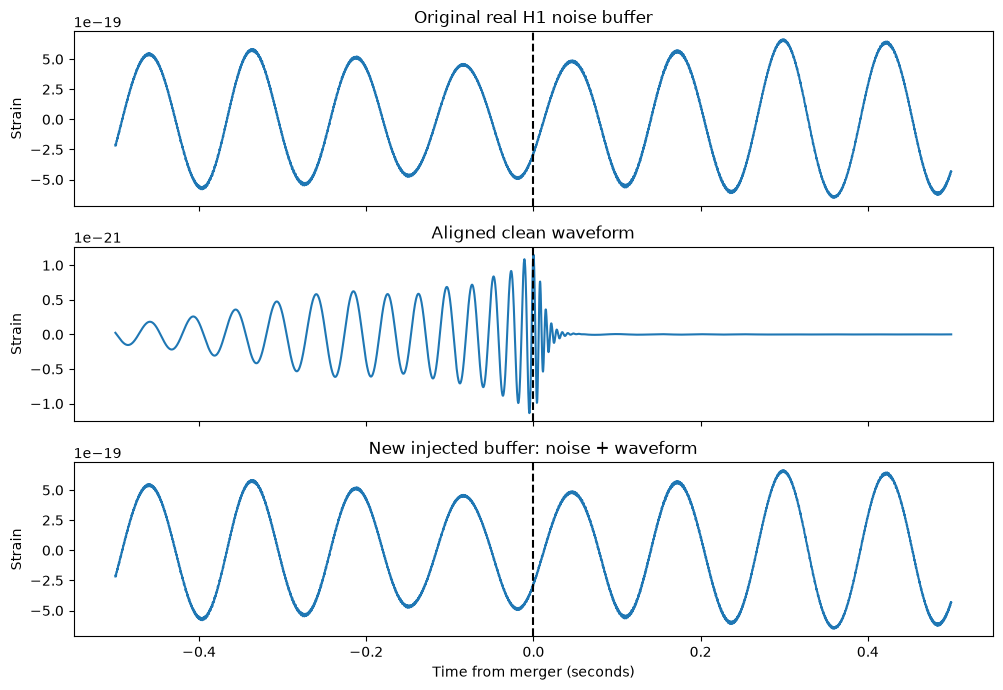

,noise_id,buffer_start_in_noise_samples,buffer_n_samples,merger_index_in_buffer,waveform_start_in_buffer,waveform_n_samples
0,H1_O3a_1239760960,978944,139264,69632,24609,65536


In [4]:
from pathlib import Path


PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Run this notebook from inside the project repository.")
    PROJECT_ROOT = PROJECT_ROOT.parent

EXPERIMENT_ID = "manual_preprocessing_v1"
EXPERIMENT_ROOT = (
    PROJECT_ROOT
    / "artifacts"
    / "manual_preprocessing_milestone"
    / EXPERIMENT_ID
)
DATA_DIR = EXPERIMENT_ROOT / "data"
SIMULATION_DIR = EXPERIMENT_ROOT / "simulation"
PREPROCESSING_DIR = EXPERIMENT_ROOT / "preprocessing"

NOISE_MANIFEST_PATH = DATA_DIR / "noise_manifest.csv"
noise_manifest = pd.read_csv(NOISE_MANIFEST_PATH)
accepted_noise_manifest = noise_manifest[
    noise_manifest["quality_status"].str.lower() == "accepted"
].copy()

assert len(accepted_noise_manifest) == 2
assert accepted_noise_manifest["noise_id"].is_unique
assert set(accepted_noise_manifest["run"]) == {"O3a", "O4a"}

noise_sources = {}
for row in accepted_noise_manifest.itertuples(index=False):
    source_path = PROJECT_ROOT / row.strain_path
    source_noise = np.load(source_path, allow_pickle=False)
    assert source_noise.ndim == 1
    assert source_noise.size == row.n_samples
    assert row.sample_rate_hz == SAMPLE_RATE_HZ
    assert np.isfinite(source_noise).all()
    noise_sources[row.noise_id] = source_noise


# Small placement example before using real noise.
practice_noise = np.zeros(20)
practice_waveform = np.array([0.1, 0.4, 1.0, 0.3, 0.1])
practice_merger_index = 10
practice_peak_index = int(np.argmax(np.abs(practice_waveform)))
practice_start = practice_merger_index - practice_peak_index
practice_stop = practice_start + len(practice_waveform)
practice_injection = practice_noise.copy()
practice_injection[practice_start:practice_stop] += practice_waveform

assert practice_start == 8
assert practice_stop == 13
assert practice_start + practice_peak_index == practice_merger_index
assert np.array_equal(practice_noise, np.zeros(20))


MIN_PADDING_SEC = 15
SAFETY_MARGIN_SEC = 2


def create_waveform_from_row(row):
    hp, hc = get_td_waveform(
        approximant=WAVEFORM_APPROXIMANT,
        mass1=float(row["mass_1"]),
        mass2=float(row["mass_2"]),
        spin1z=float(row["chi_1"]),
        spin2z=float(row["chi_2"]),
        distance=float(row["distance"]),
        inclination=0,
        coa_phase=0,
        delta_t=DELTA_T_SEC,
        f_lower=F_LOWER_HZ,
    )
    waveform = hp.numpy()
    peak_index = int(np.argmax(np.abs(waveform)))
    return {
        "hp": hp,
        "hc": hc,
        "waveform": waveform,
        "peak_index": peak_index,
    }


def inject_waveform(source_noise, waveform, peak_index, merger_index_in_noise):
    minimum_half_width = int(
        (MIN_PADDING_SEC + SAFETY_MARGIN_SEC) * SAMPLE_RATE_HZ
    )
    half_width = max(
        minimum_half_width,
        peak_index + int(SAFETY_MARGIN_SEC * SAMPLE_RATE_HZ),
        len(waveform) - peak_index + int(SAFETY_MARGIN_SEC * SAMPLE_RATE_HZ),
    )

    buffer_start = int(merger_index_in_noise - half_width)
    buffer_stop = int(merger_index_in_noise + half_width)
    waveform_start_in_noise = int(merger_index_in_noise - peak_index)
    waveform_stop_in_noise = int(waveform_start_in_noise + len(waveform))

    assert 0 <= buffer_start < buffer_stop <= len(source_noise)
    assert buffer_start <= waveform_start_in_noise
    assert waveform_stop_in_noise <= buffer_stop

    noise_buffer = source_noise[buffer_start:buffer_stop].copy()
    injected_buffer = noise_buffer.copy()
    waveform_start_in_buffer = waveform_start_in_noise - buffer_start
    waveform_stop_in_buffer = waveform_start_in_buffer + len(waveform)
    injected_buffer[waveform_start_in_buffer:waveform_stop_in_buffer] += waveform
    merger_index_in_buffer = merger_index_in_noise - buffer_start

    assert waveform_start_in_buffer + peak_index == merger_index_in_buffer
    assert merger_index_in_buffer >= MIN_PADDING_SEC * SAMPLE_RATE_HZ
    assert len(injected_buffer) - merger_index_in_buffer >= MIN_PADDING_SEC * SAMPLE_RATE_HZ
    assert np.isfinite(injected_buffer).all()

    return {
        "buffer": injected_buffer,
        "noise_buffer": noise_buffer,
        "buffer_start_in_noise_samples": buffer_start,
        "buffer_n_samples": len(injected_buffer),
        "merger_index_in_buffer": merger_index_in_buffer,
        "merger_index_in_noise": int(merger_index_in_noise),
        "waveform_start_in_buffer": waveform_start_in_buffer,
        "waveform_n_samples": len(waveform),
    }


reference_noise_row = accepted_noise_manifest.iloc[0]
reference_noise_id = reference_noise_row["noise_id"]
reference_noise = noise_sources[reference_noise_id]
reference_noise_before = reference_noise.copy()
reference_target = target_table.iloc[0]
reference_waveform = create_waveform_from_row(reference_target)
reference_merger_index = len(reference_noise) // 2
reference_injection = inject_waveform(
    reference_noise,
    reference_waveform["waveform"],
    reference_waveform["peak_index"],
    reference_merger_index,
)

assert np.array_equal(reference_noise, reference_noise_before)

aligned_waveform = np.zeros(reference_injection["buffer_n_samples"])
waveform_start = reference_injection["waveform_start_in_buffer"]
waveform_stop = waveform_start + reference_injection["waveform_n_samples"]
aligned_waveform[waveform_start:waveform_stop] = reference_waveform["waveform"]

merger_local = reference_injection["merger_index_in_buffer"]
plot_radius = int(0.5 * SAMPLE_RATE_HZ)
plot_start = merger_local - plot_radius
plot_stop = merger_local + plot_radius
plot_time = (
    np.arange(plot_start, plot_stop) - merger_local
) / SAMPLE_RATE_HZ

figure, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(
    plot_time,
    reference_injection["noise_buffer"][plot_start:plot_stop],
)
axes[0].set_title("Original real H1 noise buffer")
axes[0].set_ylabel("Strain")
axes[1].plot(plot_time, aligned_waveform[plot_start:plot_stop])
axes[1].set_title("Aligned clean waveform")
axes[1].set_ylabel("Strain")
axes[2].plot(
    plot_time,
    reference_injection["buffer"][plot_start:plot_stop],
)
axes[2].set_title("New injected buffer: noise + waveform")
axes[2].set_xlabel("Time from merger (seconds)")
axes[2].set_ylabel("Strain")
for axis in axes:
    axis.axvline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()

placement_check = pd.DataFrame([{
    "noise_id": reference_noise_id,
    "buffer_start_in_noise_samples": reference_injection["buffer_start_in_noise_samples"],
    "buffer_n_samples": reference_injection["buffer_n_samples"],
    "merger_index_in_buffer": reference_injection["merger_index_in_buffer"],
    "waveform_start_in_buffer": reference_injection["waveform_start_in_buffer"],
    "waveform_n_samples": reference_injection["waveform_n_samples"],
}])
display(placement_check)


**Cell 16**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

On October 18, 2026, I first verified peak alignment on a 20-sample practice buffer, where a five-sample waveform starting at index 8 placed its peak exactly at merger index 10. I then loaded Kennedy's two accepted H1 noise arrays using noise_id rather than row order. For a real O3a example, I generated the waveform, centered its peak on the chosen merger sample and created a copied noise buffer before adding the signal. Assertions confirmed that the original source array stayed unchanged, the complete waveform fit inside the padded buffer, at least 15 seconds remained on both sides of the merger and all values were finite. The three-panel plot shows the original noise, aligned clean waveform and resulting injection on the same merger-centered time axis. Placement metadata preserves both source-noise and local-buffer indices for downstream reconstruction.

**Cell 17**

## Task 5: Compute SNR and track selection

### Background knowledge
Optimal SNR squared is 4 times the positive-frequency integral of |h_tilde(f)| squared / PSD(f). FFT normalization, sample spacing, frequency spacing and PSD units must agree. A waveform norm is not the same as a matched-filter search over noisy data. An SNR gate changes the accepted population.

### Your task
Use Role 3 PSDs to calculate optimal SNR. Implement a frequency-sum check and compare with a library calculation on one example. Specify low/high cutoffs separately from the preprocessing band; record any departure from the existing 20 Hz lower SNR cutoff. Apply an agreed threshold, such as 8, with a finite attempt budget. Count every attempted, accepted, rejected and failed draw by run and split.

### Evidence and completion checks
Validated SNR convention and complete selection ledger; insufficient accepted examples are reported rather than hidden.

**Cell 18 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

In [5]:
from pycbc.filter import sigma
from pycbc.types import FrequencySeries
import pycbc.psd


SNR_LOW_HZ = 20
SNR_HIGH_HZ = 350
SNR_THRESHOLD = 8
ATTEMPT_BUDGET = len(target_table)
MERGER_EDGE_SEC = 65
FINAL_WINDOW_SEC = 4


psd_by_noise_id = {}
for noise_id in accepted_noise_manifest["noise_id"]:
    psd_path = PREPROCESSING_DIR / "psd" / f"{noise_id}.npz"
    with np.load(psd_path, allow_pickle=False) as psd_file:
        frequency_hz = psd_file["frequency_hz"].copy()
        psd_values = psd_file["psd_strain2_per_hz"].copy()
    assert np.all(np.diff(frequency_hz) > 0)
    assert np.isfinite(psd_values).all()
    assert (psd_values > 0).all()
    psd_by_noise_id[noise_id] = {
        "frequency_hz": frequency_hz,
        "psd": psd_values,
    }


def calculate_optimal_snr(hp, noise_id):
    psd_record = psd_by_noise_id[noise_id]
    psd_delta_f = float(
        psd_record["frequency_hz"][1]
        - psd_record["frequency_hz"][0]
    )
    base_psd = FrequencySeries(
        psd_record["psd"],
        delta_f=psd_delta_f,
    )
    interpolated_psd = pycbc.psd.interpolate(base_psd, hp.delta_f)

    library_snr = float(sigma(
        hp,
        psd=interpolated_psd,
        low_frequency_cutoff=SNR_LOW_HZ,
        high_frequency_cutoff=SNR_HIGH_HZ,
    ))

    waveform = hp.numpy()
    frequency_hz = np.fft.rfftfreq(
        len(waveform),
        d=DELTA_T_SEC,
    )
    waveform_frequency = DELTA_T_SEC * np.fft.rfft(waveform)
    manual_mask = (
        (frequency_hz >= SNR_LOW_HZ)
        & (frequency_hz <= SNR_HIGH_HZ)
    )
    manual_snr = float(np.sqrt(
        4
        * np.sum(
            np.abs(waveform_frequency[manual_mask]) ** 2
            / np.asarray(interpolated_psd)[manual_mask]
        )
        * float(hp.delta_f)
    ))

    return library_snr, manual_snr


reference_library_snr, reference_manual_snr = calculate_optimal_snr(
    reference_waveform["hp"],
    reference_noise_id,
)
reference_snr_relative_difference = abs(
    reference_library_snr - reference_manual_snr
) / reference_library_snr

assert reference_snr_relative_difference < 1e-4
print("Reference library SNR:", reference_library_snr)
print("Reference frequency-sum SNR:", reference_manual_snr)
print("Relative difference:", reference_snr_relative_difference)


noise_ids = accepted_noise_manifest["noise_id"].tolist()
assigned_noise_ids = [
    noise_ids[index % len(noise_ids)]
    for index in range(ATTEMPT_BUDGET)
]

position_by_noise_id = {}
for noise_id in noise_ids:
    number_of_attempts = assigned_noise_ids.count(noise_id)
    source_noise = noise_sources[noise_id]
    position_by_noise_id[noise_id] = np.linspace(
        MERGER_EDGE_SEC * SAMPLE_RATE_HZ,
        len(source_noise) - MERGER_EDGE_SEC * SAMPLE_RATE_HZ,
        number_of_attempts,
        dtype=int,
    )

position_counter = {noise_id: 0 for noise_id in noise_ids}
manifest_by_noise_id = accepted_noise_manifest.set_index("noise_id")
attempt_rows = []
accepted_records = []

for attempt_index, target_row in target_table.iloc[:ATTEMPT_BUDGET].iterrows():
    attempt_id = f"attempt-{attempt_index:03d}"
    noise_id = assigned_noise_ids[attempt_index]
    noise_row = manifest_by_noise_id.loc[noise_id]
    position_index = position_counter[noise_id]
    merger_index_in_noise = int(
        position_by_noise_id[noise_id][position_index]
    )
    position_counter[noise_id] += 1

    attempt_record = {
        "attempt_id": attempt_id,
        "draw_id": target_row["draw_id"],
        "sample_id": "",
        "noise_id": noise_id,
        "group_id": noise_row["group_id"],
        "run": noise_row["run"],
        "split": noise_row["split"],
        "mass_1": target_row["mass_1"],
        "mass_2": target_row["mass_2"],
        "chi_1": target_row["chi_1"],
        "chi_2": target_row["chi_2"],
        "distance": target_row["distance"],
        "chirp_mass": target_row["chirp_mass"],
        "mass_ratio": target_row["mass_ratio"],
        "chi_eff": target_row["chi_eff"],
        "snr": np.nan,
        "status": "failed",
        "reason": "not attempted",
    }

    try:
        waveform_record = create_waveform_from_row(target_row)
        library_snr, manual_snr = calculate_optimal_snr(
            waveform_record["hp"],
            noise_id,
        )
        assert np.isfinite(library_snr)
        assert abs(library_snr - manual_snr) / library_snr < 1e-4
        attempt_record["snr"] = library_snr

        if library_snr < SNR_THRESHOLD:
            attempt_record["status"] = "rejected"
            attempt_record["reason"] = "snr below threshold"
        else:
            sample_id = (
                f"{EXPERIMENT_ID}-{str(noise_row['run']).lower()}-"
                f"{attempt_index:03d}"
            )
            injection = inject_waveform(
                noise_sources[noise_id],
                waveform_record["waveform"],
                waveform_record["peak_index"],
                merger_index_in_noise,
            )
            attempt_record["sample_id"] = sample_id
            attempt_record["status"] = "accepted"
            attempt_record["reason"] = "snr at or above threshold"
            accepted_records.append({
                "sample_id": sample_id,
                "attempt_id": attempt_id,
                "noise_id": noise_id,
                "target": target_row.copy(),
                "noise_metadata": noise_row.copy(),
                "waveform": waveform_record,
                "injection": injection,
                "snr": library_snr,
            })
    except Exception as error:
        attempt_record["status"] = "failed"
        attempt_record["reason"] = f"{type(error).__name__}: {error}"

    attempt_rows.append(attempt_record)


attempts_table = pd.DataFrame(attempt_rows)
selection_counts = (
    attempts_table
    .groupby(["run", "split", "status"])
    .size()
    .rename("count")
    .reset_index()
)
display(selection_counts)

assert len(attempts_table) == ATTEMPT_BUDGET
assert attempts_table["attempt_id"].is_unique
assert len(accepted_records) == (attempts_table["status"] == "accepted").sum()
assert not (attempts_table["status"] == "failed").any()
assert (
    attempts_table.loc[
        attempts_table["status"] == "accepted",
        "snr",
    ] >= SNR_THRESHOLD
).all()


# Accepted final four-second windows may not overlap within a noise source.
final_half_width = int(FINAL_WINDOW_SEC * SAMPLE_RATE_HZ / 2)
for noise_id in noise_ids:
    intervals = sorted([
        (
            record["injection"]["merger_index_in_noise"] - final_half_width,
            record["injection"]["merger_index_in_noise"] + final_half_width,
        )
        for record in accepted_records
        if record["noise_id"] == noise_id
    ])
    if len(intervals) > 1:
        assert all(
            current[1] <= following[0]
            for current, following in zip(intervals[:-1], intervals[1:])
        )

print("Attempted:", len(attempts_table))
print("Accepted:", len(accepted_records))
print("Rejected:", (attempts_table["status"] == "rejected").sum())
print("Failed:", (attempts_table["status"] == "failed").sum())


Reference library SNR: 33.81725151418988
Reference frequency-sum SNR: 33.81725151418988
Relative difference: 0.0


,run,split,status,count
0,O3a,train,accepted,44
1,O3a,train,rejected,6
2,O4a,O4a_test,accepted,9
3,O4a,O4a_test,rejected,41


Attempted: 100
Accepted: 53
Rejected: 47
Failed: 0


**Cell 19**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

On October 18, 2026, I loaded Noah's noise-only Welch PSD for each noise_id and calculated optimal SNR from 20-350 Hz. My explicit positive-frequency sum agreed with PyCBC's sigma calculation to within the 0.01% tolerance on every attempt. I used a fixed threshold of SNR >= 8 and a finite budget of 100 parameter draws. The ledger records every accepted, rejected and failed attempt together with run, split, source IDs, parameters and reason. The pilot accepted 53 examples and rejected 47 below threshold, with no waveform or placement failures. Acceptance differed by source: 44 of 50 O3a attempts and 9 of 50 O4a attempts passed. This is evidence of selection under these two particular PSDs, not enough evidence to claim general O3a-to-O4a detector drift. All retained four-second crop intervals are nonoverlapping within each source record.

**Cell 20**

## Task 6: Export labels and analyze selection

### Background knowledge
Accepted injections are a selected population. Different PSDs can produce different rejection rates even with identical draw rules. Target correlations may arise from shared component parameters, not learned model importance.

### Your task
Export buffers/manifests/targets. Plot accepted target and SNR distributions by run; compare attempted versus accepted parameter draws where possible. Make a target correlation heatmap and a distance-SNR scatter plot. Interpret selection effects and confirm that Role 3 can reconstruct one buffer/time position. Prepare 150 words and a contribution log.

### Evidence and completion checks
Detailed population EDA, actual counts and an accepted-ID handoff; do not assert noise-induced drift from these plots alone.

**Cell 21 is your empty work cell.** Write your own implementation if this task needs code. For planning/writing-only tasks, leave it empty and complete your response below. Do not train a model merely to fill a cell.

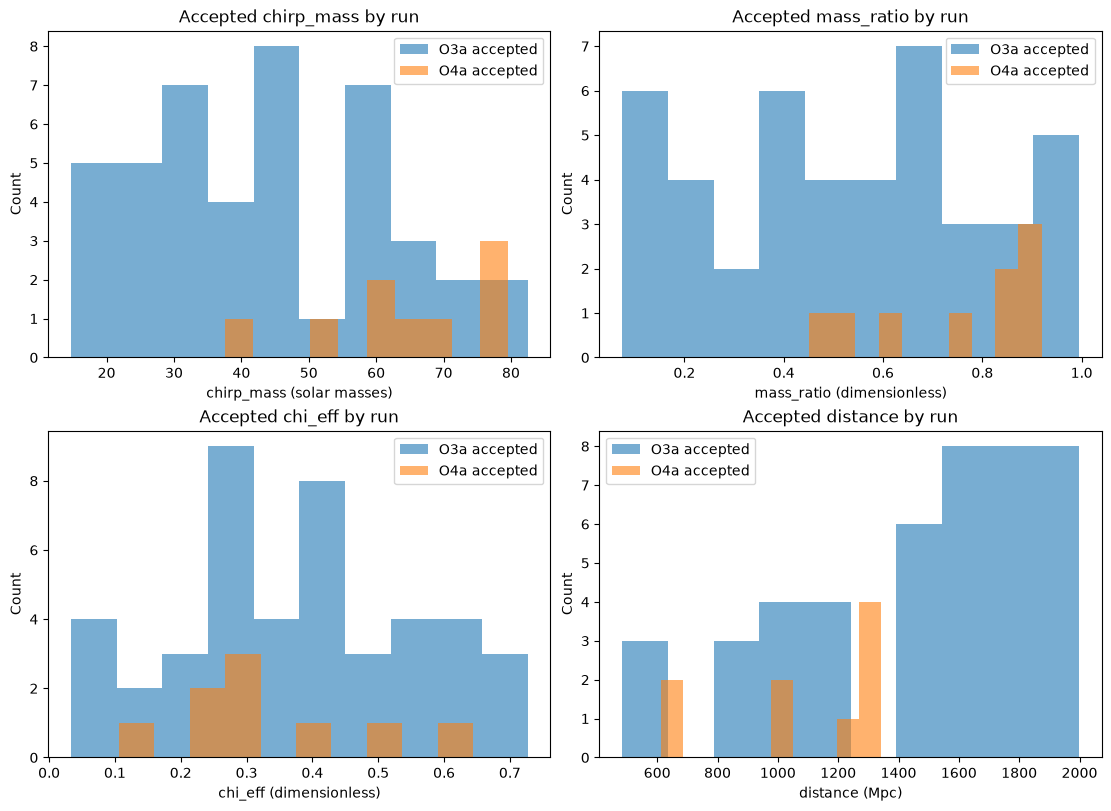

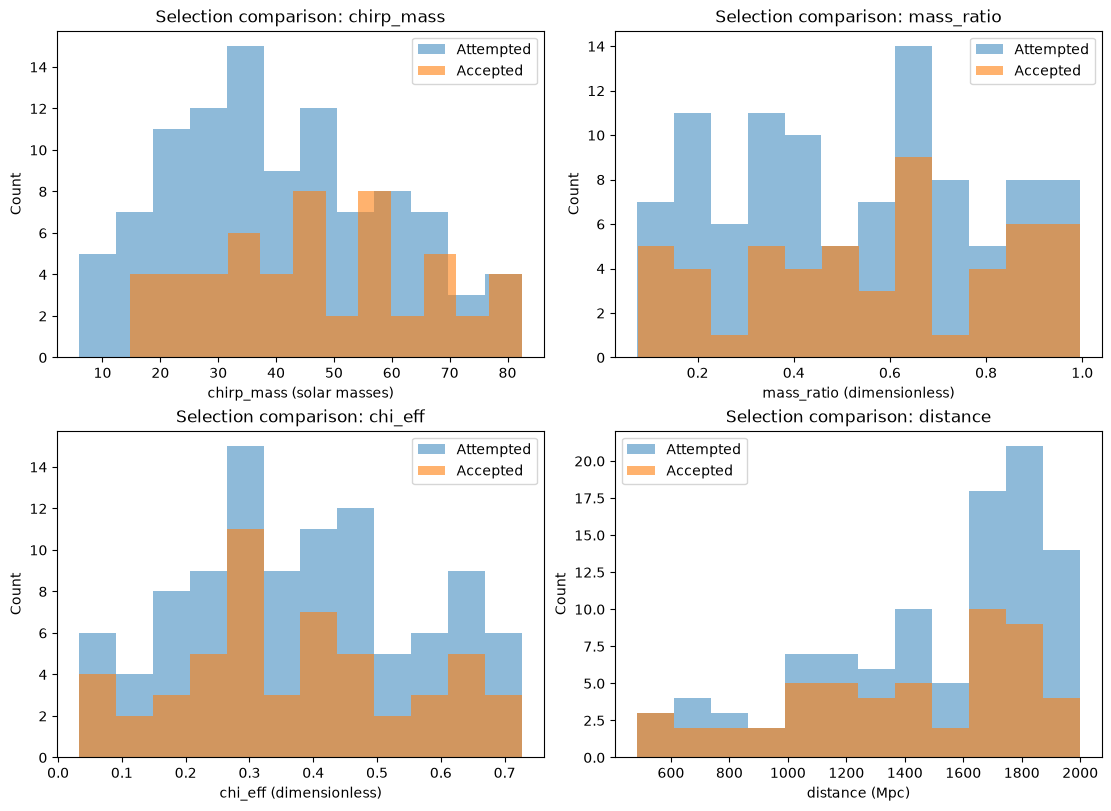

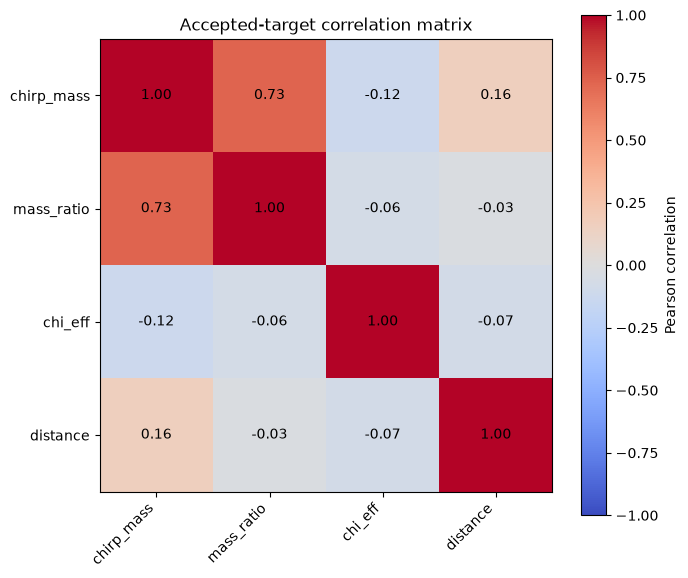

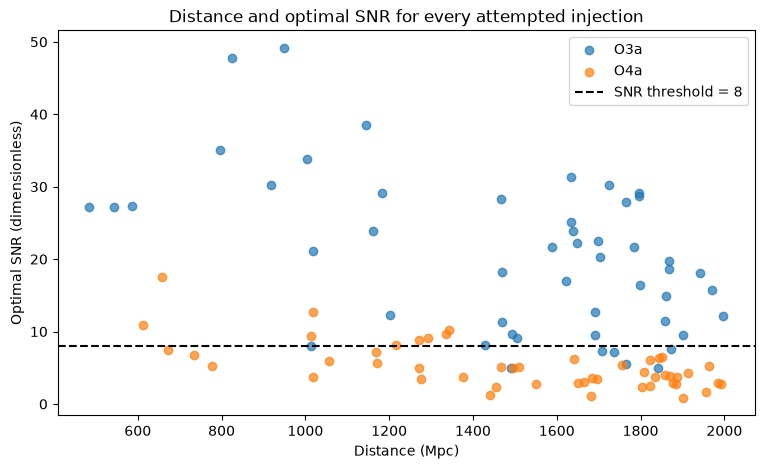

,sample_id,noise_id,group_id,run,split,buffer_shape,reconstruction_matches
0,manual_preprocessing_v1-o3a-000,H1_O3a_1239760960,O3a_g01,O3a,train,"(139264,)",True


Exported attempts: /Users/aaronrassiq/Documents/obsidian-data/Berkeley/DATASCI-207/finalproject/ligo-parameter-inference/artifacts/manual_preprocessing_milestone/manual_preprocessing_v1/simulation/attempts.csv
Exported manifest: /Users/aaronrassiq/Documents/obsidian-data/Berkeley/DATASCI-207/finalproject/ligo-parameter-inference/artifacts/manual_preprocessing_milestone/manual_preprocessing_v1/simulation/injection_manifest.csv
Exported targets: /Users/aaronrassiq/Documents/obsidian-data/Berkeley/DATASCI-207/finalproject/ligo-parameter-inference/artifacts/manual_preprocessing_milestone/manual_preprocessing_v1/simulation/targets.csv
Exported buffers: 53


In [6]:
import json


BUFFER_DIR = SIMULATION_DIR / "buffers"
BUFFER_DIR.mkdir(parents=True, exist_ok=True)

injection_manifest_rows = []
target_rows = []

for record in accepted_records:
    sample_id = record["sample_id"]
    buffer_path = BUFFER_DIR / f"{sample_id}.npy"
    np.save(buffer_path, record["injection"]["buffer"], allow_pickle=False)

    noise_metadata = record["noise_metadata"]
    injection = record["injection"]
    target = record["target"]

    injection_manifest_rows.append({
        "sample_id": sample_id,
        "noise_id": record["noise_id"],
        "group_id": noise_metadata["group_id"],
        "run": noise_metadata["run"],
        "split": noise_metadata["split"],
        "buffer_path": buffer_path.relative_to(PROJECT_ROOT).as_posix(),
        "buffer_start_in_noise_samples": injection["buffer_start_in_noise_samples"],
        "buffer_n_samples": injection["buffer_n_samples"],
        "merger_index_in_buffer": injection["merger_index_in_buffer"],
        "waveform_start_in_buffer": injection["waveform_start_in_buffer"],
        "waveform_n_samples": injection["waveform_n_samples"],
        "snr": record["snr"],
        "status": "accepted",
    })

    target_rows.append({
        "sample_id": sample_id,
        "mass_1": target["mass_1"],
        "mass_2": target["mass_2"],
        "chi_1": target["chi_1"],
        "chi_2": target["chi_2"],
        "distance": target["distance"],
        "chirp_mass": target["chirp_mass"],
        "mass_ratio": target["mass_ratio"],
        "chi_eff": target["chi_eff"],
    })


injection_manifest = pd.DataFrame(injection_manifest_rows)
targets_export = pd.DataFrame(target_rows)

SIMULATION_DIR.mkdir(parents=True, exist_ok=True)
attempts_table.to_csv(SIMULATION_DIR / "attempts.csv", index=False)
injection_manifest.to_csv(
    SIMULATION_DIR / "injection_manifest.csv",
    index=False,
)
targets_export.to_csv(SIMULATION_DIR / "targets.csv", index=False)

simulation_settings = {
    "experiment_id": EXPERIMENT_ID,
    "owner": "Aaron Rassiq (Role 2)",
    "sample_rate_hz": SAMPLE_RATE_HZ,
    "waveform_approximant": WAVEFORM_APPROXIMANT,
    "f_lower_hz": F_LOWER_HZ,
    "inclination": 0,
    "coa_phase": 0,
    "polarization_convention": "h_plus only; not a full detector projection",
    "snr_low_hz": SNR_LOW_HZ,
    "snr_high_hz": SNR_HIGH_HZ,
    "snr_threshold": SNR_THRESHOLD,
    "attempt_budget": ATTEMPT_BUDGET,
    "seed": SEED,
    "target_order": TARGET_ORDER,
    "units": {
        "mass_1": "solar masses",
        "mass_2": "solar masses",
        "chi_1": "dimensionless",
        "chi_2": "dimensionless",
        "distance": "Mpc",
        "chirp_mass": "solar masses",
        "mass_ratio": "dimensionless",
        "chi_eff": "dimensionless",
        "snr": "dimensionless",
    },
    "counts": {
        "attempted": int(len(attempts_table)),
        "accepted": int((attempts_table["status"] == "accepted").sum()),
        "rejected": int((attempts_table["status"] == "rejected").sum()),
        "failed": int((attempts_table["status"] == "failed").sum()),
    },
}

with open(SIMULATION_DIR / "simulation_settings.json", "w") as settings_file:
    json.dump(simulation_settings, settings_file, indent=2)


assert injection_manifest["sample_id"].is_unique
assert targets_export["sample_id"].is_unique
assert set(injection_manifest["sample_id"]) == set(targets_export["sample_id"])
assert len(injection_manifest) == simulation_settings["counts"]["accepted"]
assert np.isfinite(targets_export.drop(columns="sample_id").to_numpy()).all()


accepted_analysis = (
    injection_manifest[
        ["sample_id", "run", "split", "snr"]
    ]
    .merge(targets_export, on="sample_id", validate="one_to_one")
)

figure, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for axis, column, unit in zip(
        axes.flat,
        TARGET_ORDER,
        ["solar masses", "dimensionless", "dimensionless", "Mpc"],
        ):
    for run_name, run_rows in accepted_analysis.groupby("run"):
        axis.hist(
            run_rows[column],
            bins=10,
            alpha=0.6,
            label=f"{run_name} accepted",
        )
    axis.set_title(f"Accepted {column} by run")
    axis.set_xlabel(f"{column} ({unit})")
    axis.set_ylabel("Count")
    axis.legend()
plt.show()


figure, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for axis, column, unit in zip(
        axes.flat,
        TARGET_ORDER,
        ["solar masses", "dimensionless", "dimensionless", "Mpc"],
        ):
    axis.hist(
        attempts_table[column],
        bins=12,
        alpha=0.5,
        label="Attempted",
    )
    axis.hist(
        attempts_table.loc[attempts_table["status"] == "accepted", column],
        bins=12,
        alpha=0.6,
        label="Accepted",
    )
    axis.set_title(f"Selection comparison: {column}")
    axis.set_xlabel(f"{column} ({unit})")
    axis.set_ylabel("Count")
    axis.legend()
plt.show()


correlation = accepted_analysis[TARGET_ORDER].corr()
figure, axis = plt.subplots(figsize=(7, 6))
image = axis.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
axis.set_xticks(range(len(TARGET_ORDER)), TARGET_ORDER, rotation=45, ha="right")
axis.set_yticks(range(len(TARGET_ORDER)), TARGET_ORDER)
for row_index in range(len(TARGET_ORDER)):
    for column_index in range(len(TARGET_ORDER)):
        axis.text(
            column_index,
            row_index,
            f"{correlation.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center",
        )
axis.set_title("Accepted-target correlation matrix")
figure.colorbar(image, ax=axis, label="Pearson correlation")
plt.tight_layout()
plt.show()


figure, axis = plt.subplots(figsize=(9, 5))
for run_name, run_rows in attempts_table.groupby("run"):
    axis.scatter(
        run_rows["distance"],
        run_rows["snr"],
        alpha=0.7,
        label=run_name,
    )
axis.axhline(
    SNR_THRESHOLD,
    color="black",
    linestyle="--",
    label=f"SNR threshold = {SNR_THRESHOLD}",
)
axis.set_title("Distance and optimal SNR for every attempted injection")
axis.set_xlabel("Distance (Mpc)")
axis.set_ylabel("Optimal SNR (dimensionless)")
axis.legend()
plt.show()


# Reload one exported record using only its manifests and verify placement.
handoff_row = injection_manifest.iloc[0]
handoff_target = targets_export.set_index("sample_id").loc[
    handoff_row["sample_id"]
]
handoff_noise_row = accepted_noise_manifest.set_index("noise_id").loc[
    handoff_row["noise_id"]
]
handoff_noise = np.load(
    PROJECT_ROOT / handoff_noise_row["strain_path"],
    allow_pickle=False,
)
handoff_buffer = np.load(
    PROJECT_ROOT / handoff_row["buffer_path"],
    allow_pickle=False,
)
handoff_waveform = create_waveform_from_row(handoff_target)

buffer_start = int(handoff_row["buffer_start_in_noise_samples"])
expected_buffer = handoff_noise[
    buffer_start:buffer_start + int(handoff_row["buffer_n_samples"])
].copy()
waveform_start = int(handoff_row["waveform_start_in_buffer"])
waveform_stop = waveform_start + int(handoff_row["waveform_n_samples"])
expected_buffer[waveform_start:waveform_stop] += handoff_waveform["waveform"]

assert np.array_equal(handoff_buffer, expected_buffer)
assert (
    waveform_start + handoff_waveform["peak_index"]
    == handoff_row["merger_index_in_buffer"]
)

handoff_check = pd.DataFrame([{
    "sample_id": handoff_row["sample_id"],
    "noise_id": handoff_row["noise_id"],
    "group_id": handoff_row["group_id"],
    "run": handoff_row["run"],
    "split": handoff_row["split"],
    "buffer_shape": handoff_buffer.shape,
    "reconstruction_matches": np.array_equal(handoff_buffer, expected_buffer),
}])
display(handoff_check)

print("Exported attempts:", SIMULATION_DIR / "attempts.csv")
print("Exported manifest:", SIMULATION_DIR / "injection_manifest.csv")
print("Exported targets:", SIMULATION_DIR / "targets.csv")
print("Exported buffers:", len(list(BUFFER_DIR.glob("*.npy"))))


**Cell 22**

### Your findings and contribution record

- What did you do personally, and on what date?
- What measured counts, plots or checks support your answer?
- What are the units, IDs and assumptions?
- What failed, remains planned or needs a teammate's input?
- What will you hand off?

**Your response:**

On October 18, 2026, I exported 100 attempt records, 53 accepted injection buffers, the accepted target table, injection manifest and simulation settings under manual_preprocessing_v1/simulation. Every accepted sample_id joins one-to-one between its buffer metadata and labels. The accepted population contains 44 O3a/train and 9 O4a/O4a_test examples from one source group per run. The attempted-versus-accepted plots show that the SNR threshold changes the simulated population, particularly by favoring stronger combinations of mass and distance. The distance-SNR plot shows the expected general decline in SNR with distance, with scatter caused by masses, spins and the run-specific PSD. Target correlations describe the accepted simulator population and are not model feature importance. I also reconstructed one exported buffer directly from its source-noise interval, target row and placement indices, confirming exact equality and peak alignment. This pilot is intentionally small: one group per run cannot support the full proposed train/validation/test design or establish population-level detector drift. The handoff is ready for Role 3 preprocessing.

**Cell 23**

## Milestone completion and handoff

Before marking your role complete, show the teammate consuming your artifacts one real record and its provenance. Give them a settings file, retained/rejected counts and a short interpretation, not just an array. Check sample_id, noise_id, group_id, run, split and shape at the handoff. Save outputs under your role-owned folder for the same experiment_id.

Deliver your completed notebook, a contribution log, 100-150 words of findings, figures with descriptive titles/axes/units/legends/captions and an explicit list of unfinished checks. Do not copy another person's implementation into your notebook. Preserve the older notebooks and existing PDFs.

**Stop at this checkpoint:** dataset preparation, validated preprocessing and EDA, exact allocation tables and the three-algorithm methodology plan. Full linear/Ridge/SNPE training, final model ranking, posterior calibration results and 800-per-run manual regeneration are not mandatory tasks in this set. Feature importance remains an acknowledged rubric gap if deferred; the team must decide how to complete that requirement before submission rather than asserting full compliance.

**Write a final reflection:** What did you personally implement? What evidence supports it? Which decisions need another owner's agreement? Which findings belong to the new pilot rather than the historical project? What remains before submission?


**Final reflection:**

I implemented the Role 2 manual pilot from parameter priors through waveform generation, derived labels, real-noise placement, PSD-based SNR selection and artifact export. The evidence includes reproducible assertions, clean-waveform comparisons, a complete attempt ledger, accepted-population plots and an exact reconstruction of one exported buffer. Kennedy's Role 1 handoff supplied two real H1 source arrays and Noah's Role 3 notebook supplied their matching PSDs. The new results belong only to manual_preprocessing_v1 and do not replace the historical 800-per-run dataset. Before submission, Role 3 must rerun its real preprocessing path on these buffers, Role 4 must audit the counts and the team must decide whether the one-group-per-run pilot is sufficient or should be expanded. The current pilot cannot test validation/O3a-test splits or support a general detector-drift conclusion.

**Final reflection:**

I implemented the Role 2 manual pilot from parameter priors through waveform generation, derived labels, real-noise placement, PSD-based SNR selection and artifact export. The evidence includes reproducible assertions, clean-waveform comparisons, a complete attempt ledger, accepted-population plots and an exact reconstruction of one exported buffer. Kennedy's Role 1 handoff supplied two real H1 source arrays and Noah's Role 3 notebook supplied their matching PSDs. The new results belong only to manual_preprocessing_v1 and do not replace the historical 800-per-run dataset. Before submission, Role 3 must rerun its real preprocessing path on these buffers, Role 4 must audit the counts and the team must decide whether the one-group-per-run pilot is sufficient or should be expanded. The current pilot cannot test validation/O3a-test splits or support a general detector-drift conclusion.

**Cell 24**

## Background references

- [GWOSC data](https://gwosc.org/data/)
- [PyCBC waveforms](https://pycbc.org/pycbc/latest/html/waveform.html)
- [SciPy signal processing](https://docs.scipy.org/doc/scipy/reference/signal.html)
- [sbi calibration guide](https://sbi.readthedocs.io/en/latest/how_to_guide/16_sbc.html)

Consult library documentation for concepts and conventions. Your notebook should contain your own implementation and interpretation.